# Liver/HepG2 MPRA and Base Editing Variant Effects

This notebook provides an IGVF Integrative Analysis Working Group (IAWG) example showing how IGVF consortium datasets can be combined for an interactive comparative analysis. It compares liver/HepG2 MPRA emVar calls with Sherwood CRISPR base-editing LDL uptake measurements.

The key visual summaries are loaded from processed analysis outputs, then the underlying tables are inspected and the main plots are regenerated in notebook cells.


In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from scipy.stats import mannwhitneyu, pearsonr, spearmanr

def find_iawg_root(start=Path.cwd()):
    for path in [start.resolve(), *start.resolve().parents]:
        if (path / 'Data/processed/Liver_MPRA_VS_BE').exists():
            return path
    raise FileNotFoundError('Could not find Data/processed/Liver_MPRA_VS_BE above the current working directory.')

def first_existing_path(*paths):
    for path in paths:
        if path.exists():
            return path
    return paths[-1]

ROOT = find_iawg_root()
OUTDIR = ROOT / 'Data/processed/Liver_MPRA_VS_BE'
PLOTDIR = first_existing_path(Path('../plots/Liver_MPRA_vs_BE'), OUTDIR)
CALLS = OUTDIR / 'emvar_calls.tsv'
SUMMARY = OUTDIR / 'emvar_summary.tsv'
CORR = OUTDIR / 'emvar_be_correlations.tsv'
VENN = OUTDIR / 'mpra_be_venn_counts.tsv'

pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')
OUTDIR.relative_to(ROOT)


PosixPath('Data/processed/Liver_MPRA_VS_BE')

## Existing Dashboard Figures

These are the reference figures already produced in `Liver_MPRA_VS_BE`. The rest of the notebook uses the same derived tables and thresholds.

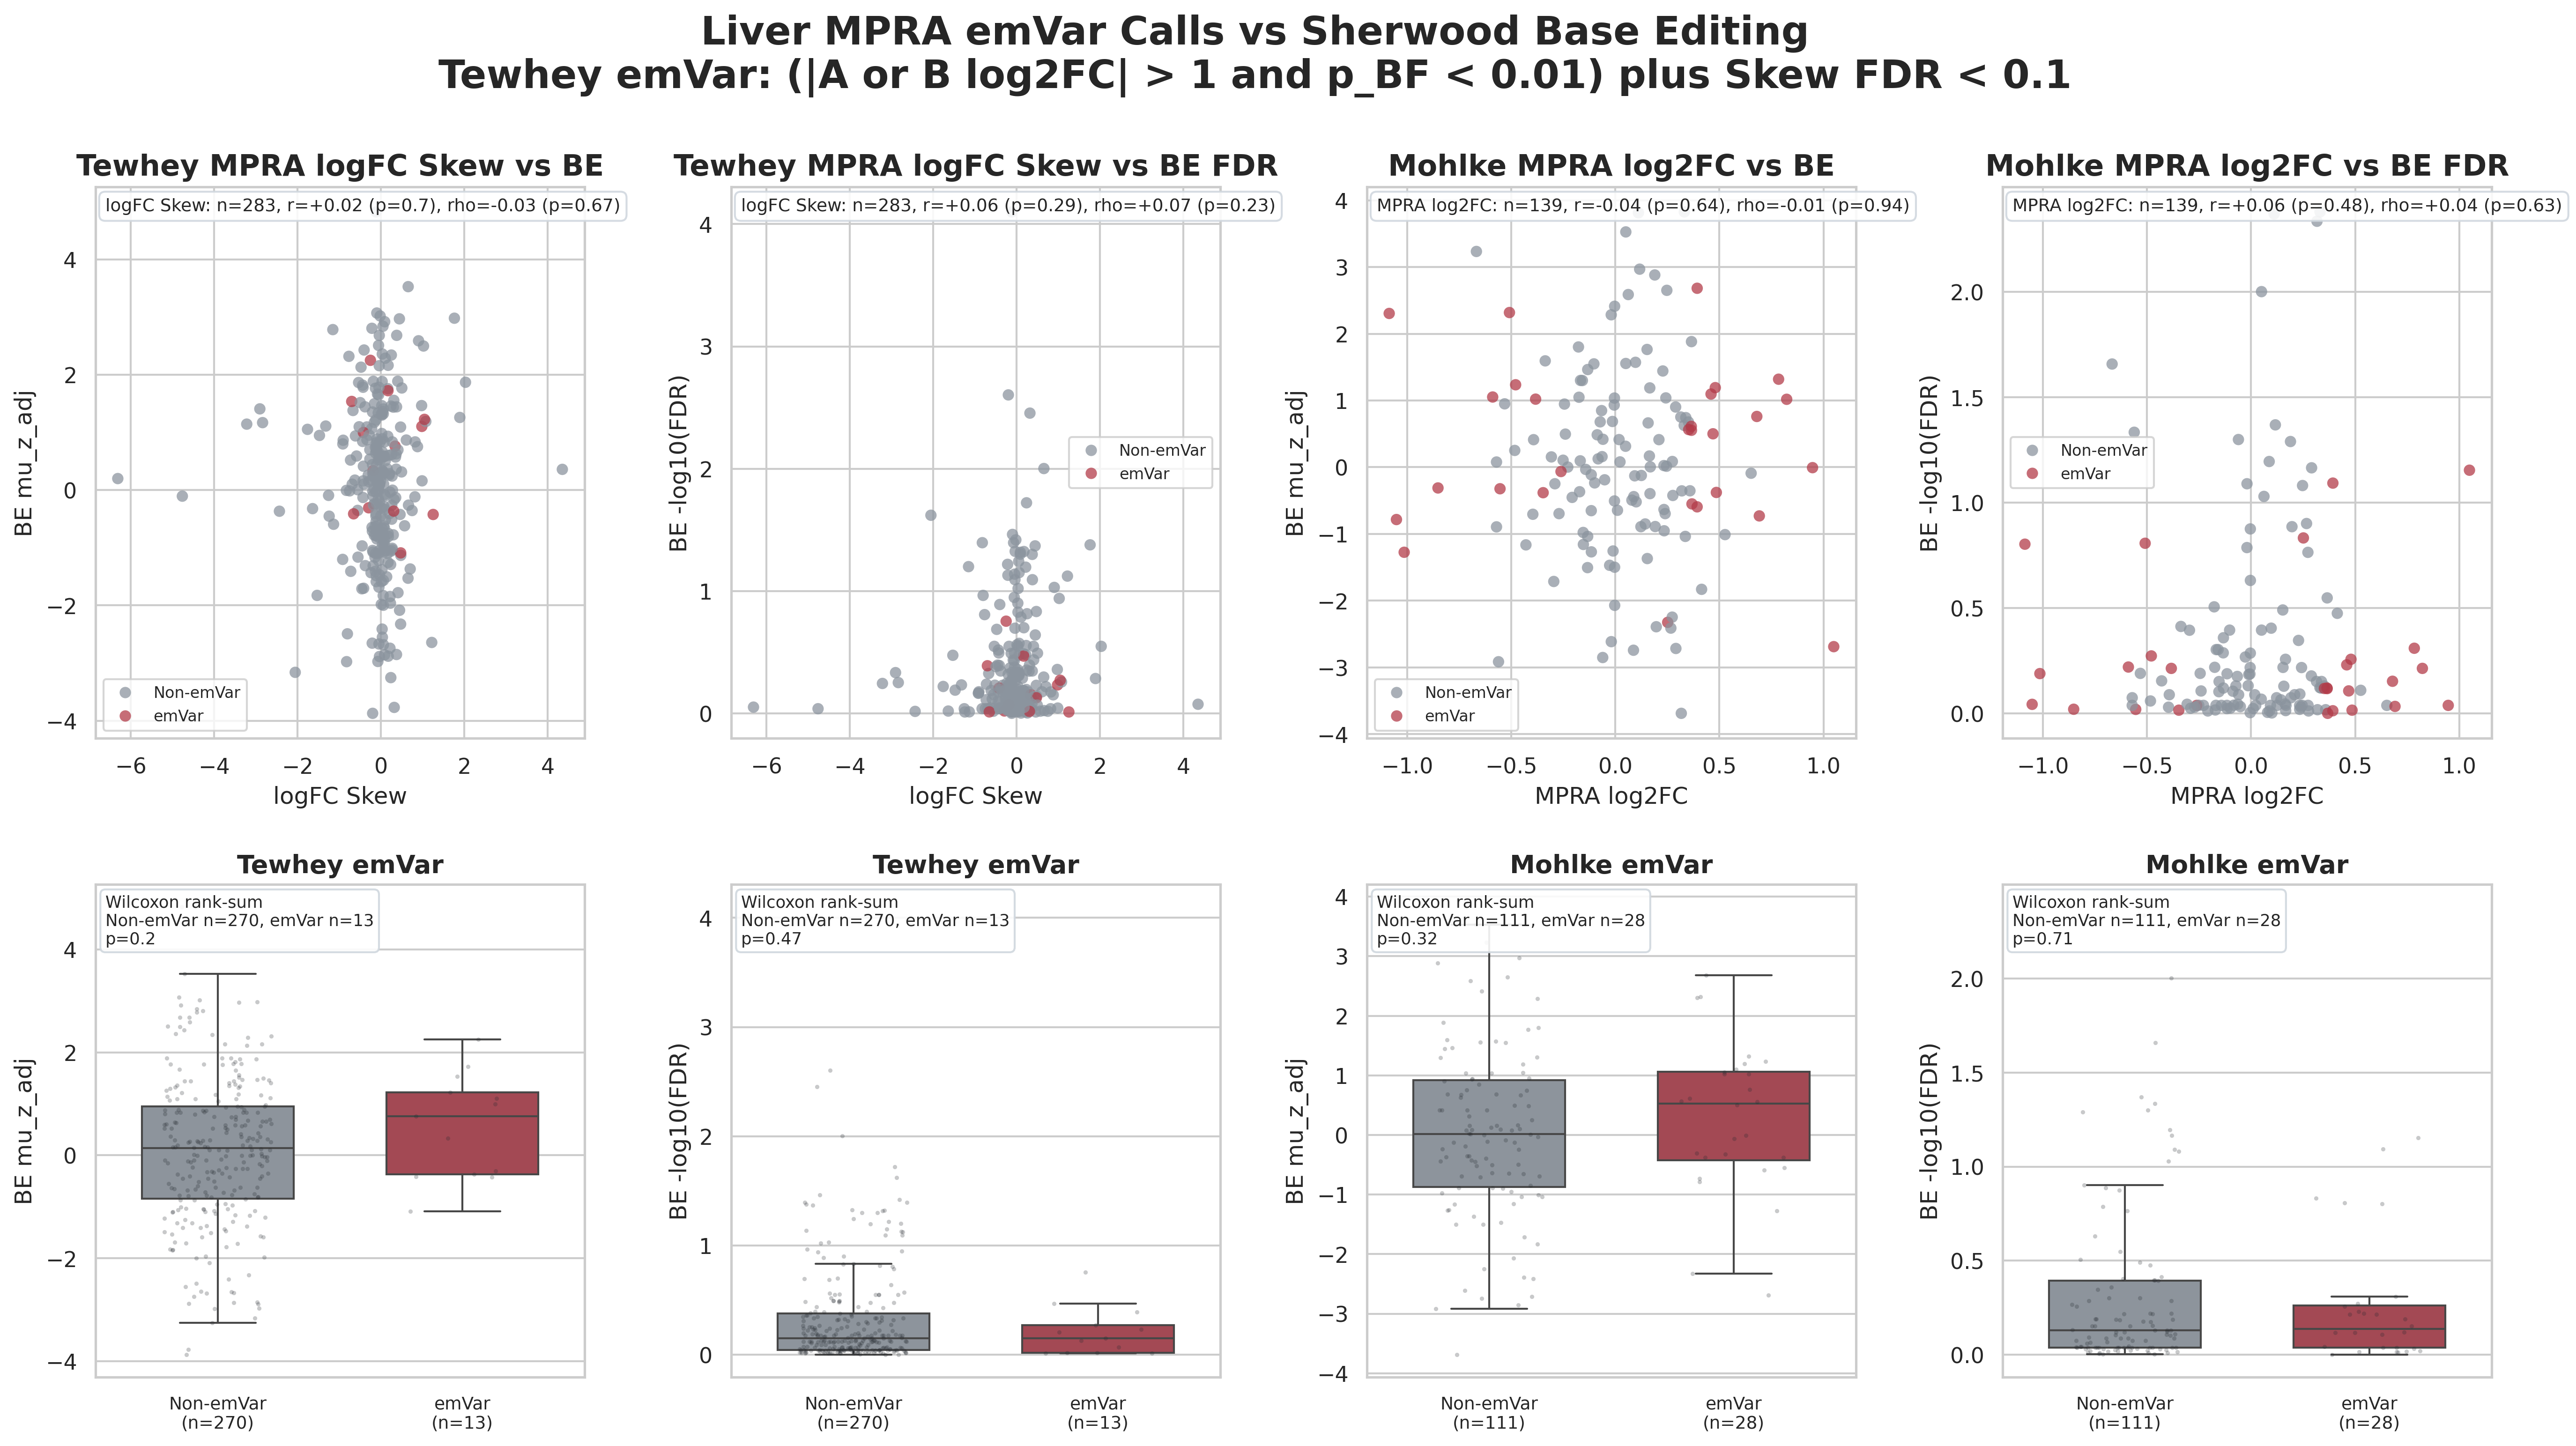

In [2]:
display(Image(filename=str(PLOTDIR / 'liver_emvar_be_dashboard_onepage.png')))

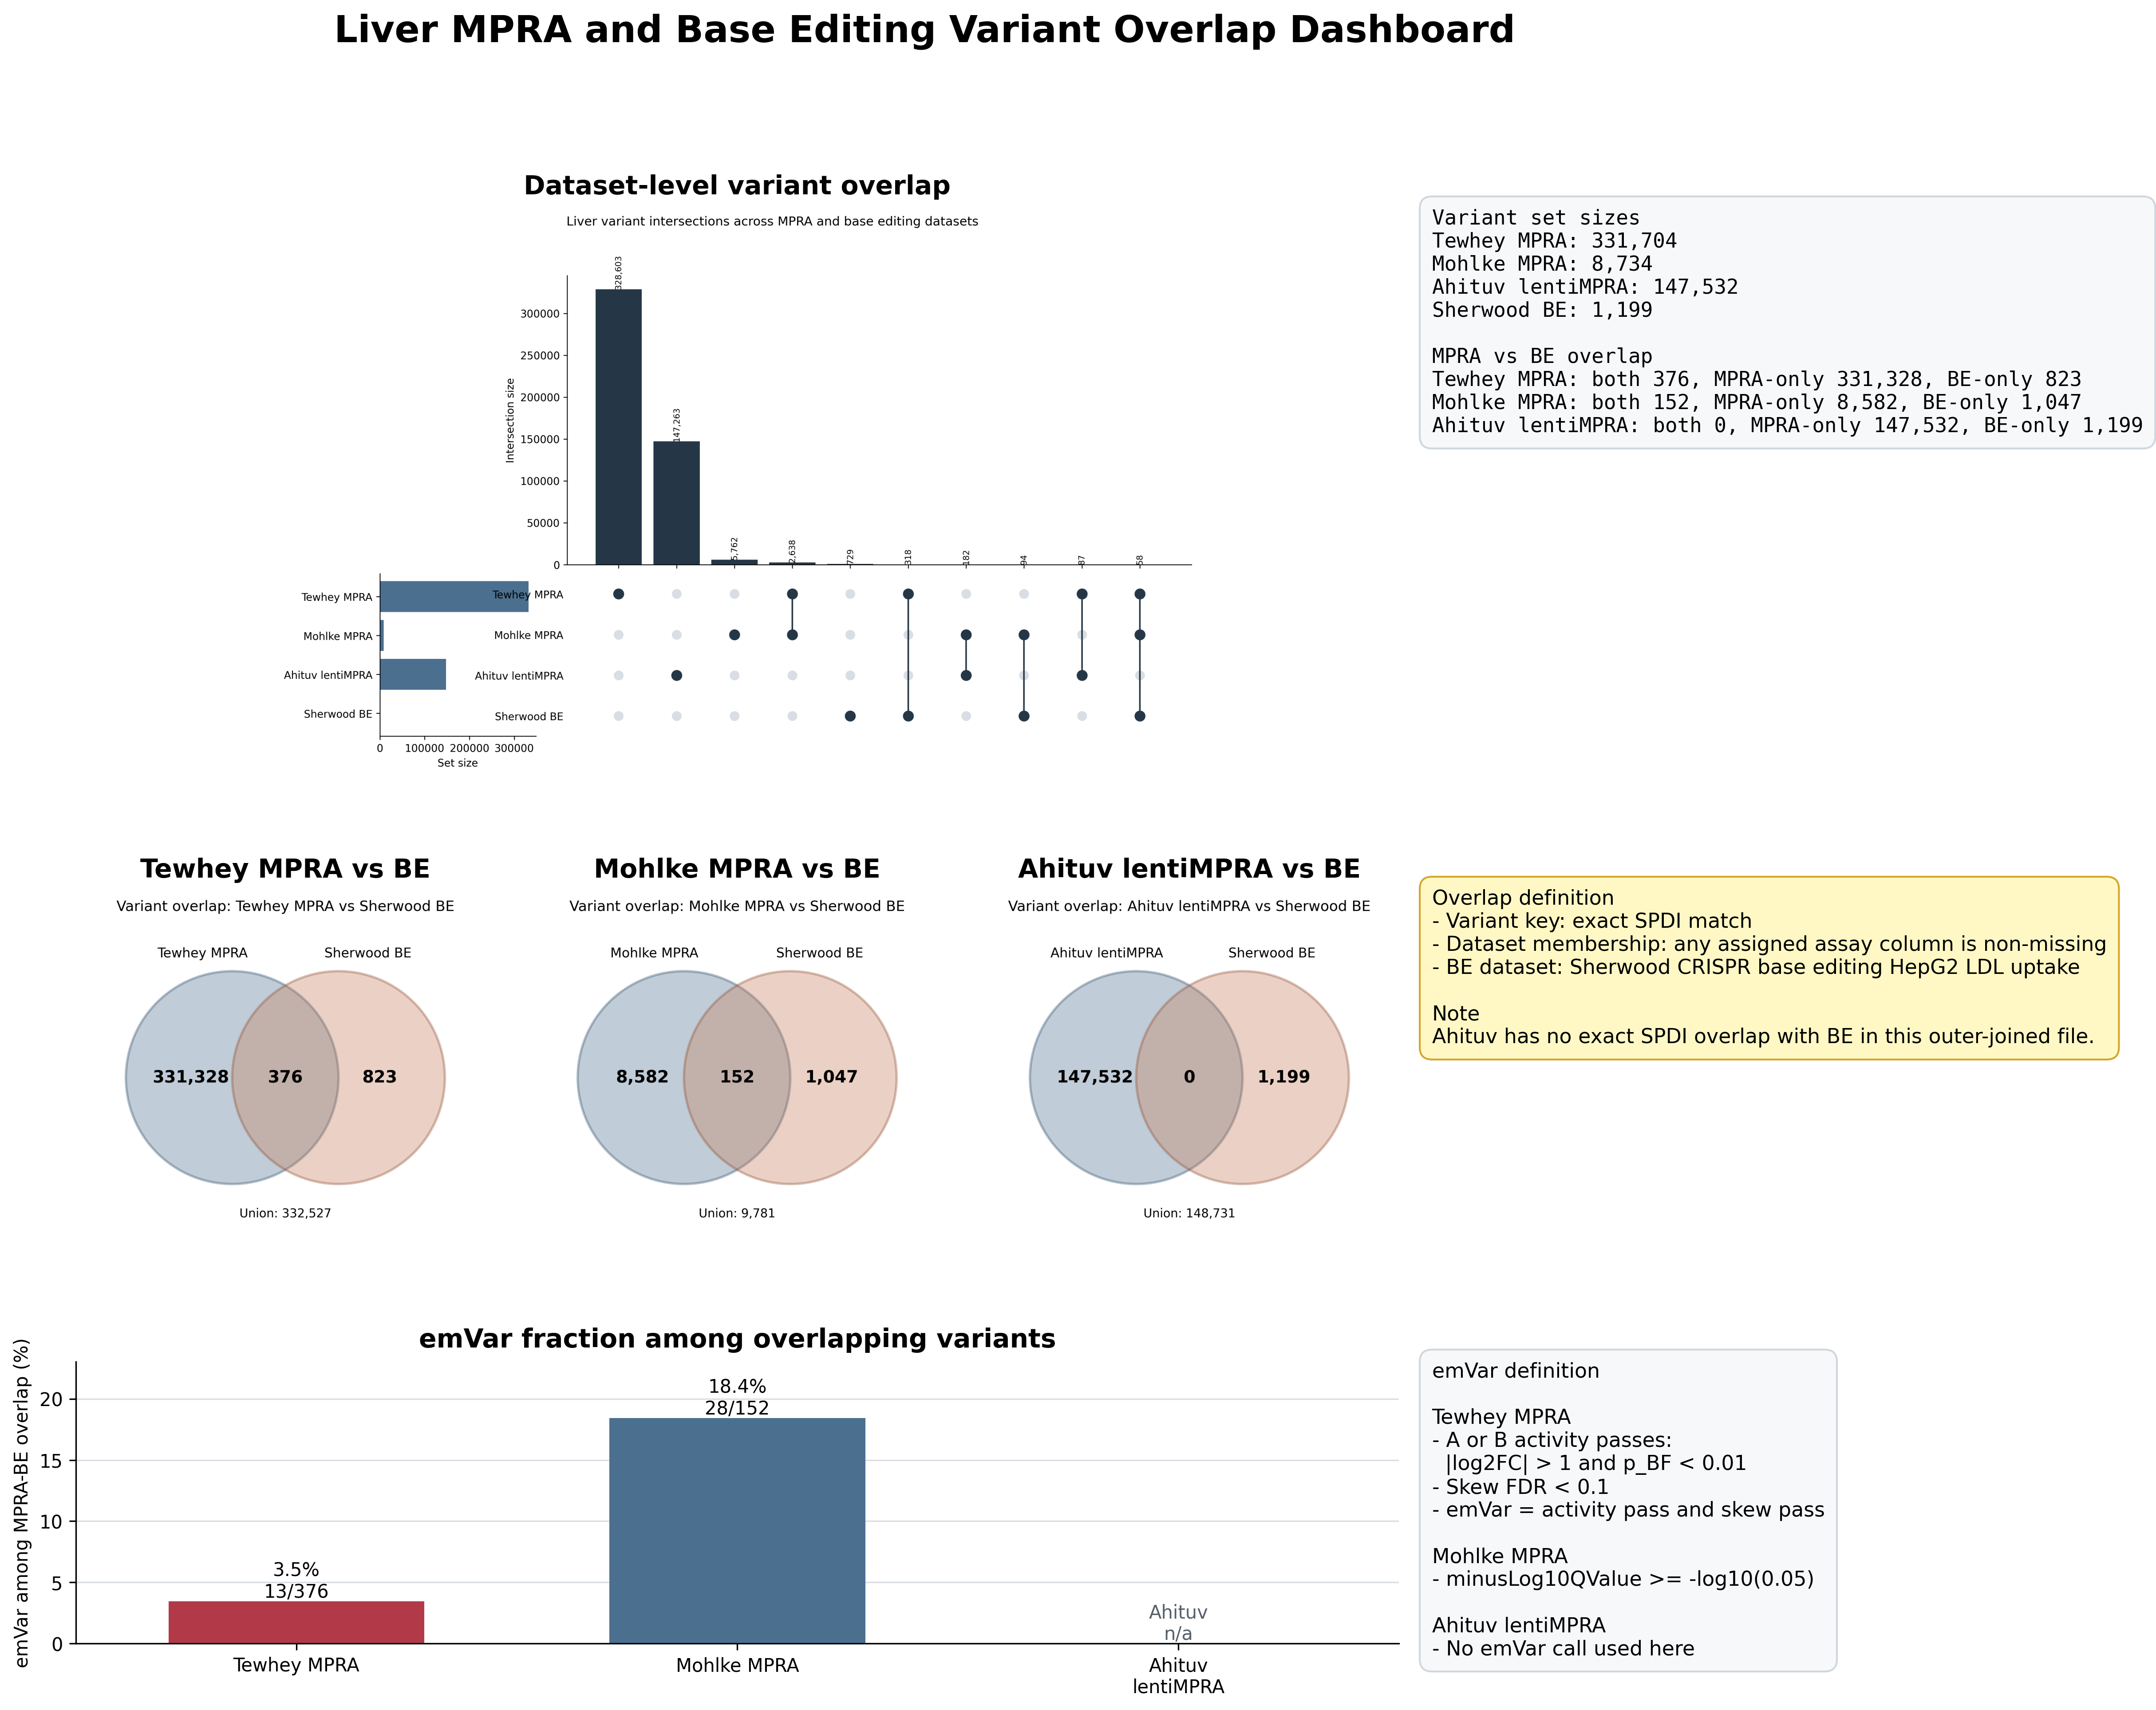

In [3]:
display(Image(filename=str(PLOTDIR / 'liver_variant_overlap_dashboard.png')))

## Load Processed Tables

`emvar_calls.tsv` contains the analysis-ready variant table with MPRA metrics, derived emVar labels, and Sherwood BE metrics.

In [4]:
calls = pd.read_csv(CALLS, sep='	', low_memory=False)
summary = pd.read_csv(SUMMARY, sep='	')
corr = pd.read_csv(CORR, sep='	')
venn = pd.read_csv(VENN, sep='	')

print(f'emVar call table: {calls.shape[0]:,} variants x {calls.shape[1]:,} columns')
display(summary)
display(corr)
display(venn)

emVar call table: 311,431 variants x 20 columns


,dataset,class,variant_count,with_BE_count
0,Tewhey,Non-emVar,287661,270
1,Tewhey,emVar,16061,13
2,Mohlke,Non-emVar,6635,111
3,Mohlke,emVar,1976,28


,dataset,mpra_metric,be_metric,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,Tewhey,Tewhey_ENCODE_HepG2_MPRA_Log2Skew,Sherwood_CRISPRBaseEditing_HepG2_LDLuptake.mu_...,283,0.022826,0.702210,-0.025394,0.670564
1,Tewhey,Tewhey_ENCODE_HepG2_MPRA_Log2Skew,BE_neg_log10_fdr,283,0.063614,0.286195,0.071560,0.230126
2,Mohlke,Mohlke_HepG2_MPRA.log2FC,Sherwood_CRISPRBaseEditing_HepG2_LDLuptake.mu_...,139,-0.039989,0.640221,-0.006265,0.941651
3,Mohlke,Mohlke_HepG2_MPRA.log2FC,BE_neg_log10_fdr,139,0.060248,0.481096,0.041635,0.626504


,mpra_dataset,mpra_only,be_only,both,union
0,Tewhey_ENCODE_HepG2_MPRA,331328,823,376,332527
1,Mohlke_HepG2_MPRA,8582,1047,152,9781
2,Ahituv_HepG2_lentiMPRA,147532,1199,0,148731


## Definitions Used Here

- **Tewhey MPRA emVar**: `(A or B activity passes: |log2FC| > 1 and p_BF < 0.01) plus Skew FDR < 0.1`.
- **Mohlke MPRA emVar**: `minusLog10QValue >= -log10(0.05)`.
- **BE signal**: Sherwood `mu_z_adj` and `-log10(fdr_adj)`.
- **Overlap**: exact SPDI match in the outer-joined liver table.

In [5]:
TEWHEY_SKEW_FC = 'Tewhey_ENCODE_HepG2_MPRA_Log2Skew'
MOHLKE_FC = 'Mohlke_HepG2_MPRA.log2FC'
BE_MU = 'Sherwood_CRISPRBaseEditing_HepG2_LDLuptake.mu_z_adj'
BE_FDR = 'Sherwood_CRISPRBaseEditing_HepG2_LDLuptake.fdr_adj'
BE_LOGFDR = 'BE_neg_log10_fdr'

BINARY_ORDER = ['Non-emVar', 'emVar']
BINARY_PALETTE = {'Non-emVar': '#8B949E', 'emVar': '#B23A48'}

for col in [TEWHEY_SKEW_FC, MOHLKE_FC, BE_MU, BE_FDR, BE_LOGFDR]:
    calls[col] = pd.to_numeric(calls[col], errors='coerce')

summary_pivot = summary.pivot(index='dataset', columns='class', values=['variant_count', 'with_BE_count'])
summary_pivot

variant_count        with_BE_count      
class       Non-emVar  emVar     Non-emVar emVar
dataset                                         
Mohlke           6635   1976           111    28
Tewhey         287661  16061           270    13

## MPRA-BE Variant Overlap

The overlap dashboard shows that Sherwood BE has limited exact-SPDI overlap with these MPRA datasets, and Ahituv lentiMPRA has no exact overlap with BE in this joined file.

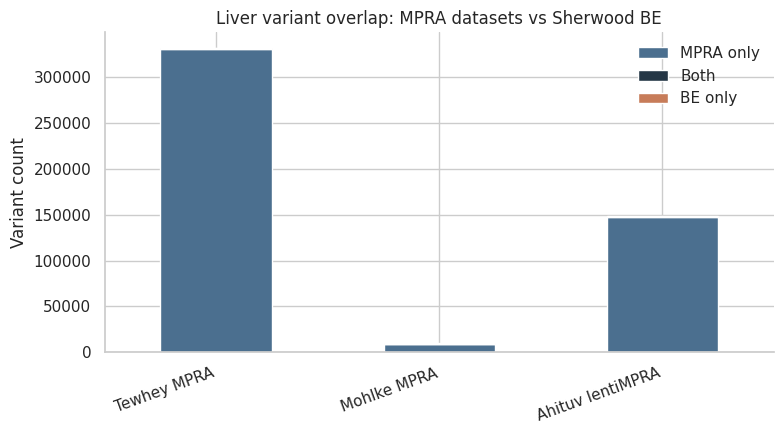

In [6]:
plot_df = venn.copy()
plot_df['mpra_label'] = plot_df['mpra_dataset'].map({
    'Tewhey_ENCODE_HepG2_MPRA': 'Tewhey MPRA',
    'Mohlke_HepG2_MPRA': 'Mohlke MPRA',
    'Ahituv_HepG2_lentiMPRA': 'Ahituv lentiMPRA',
})
plot_df = plot_df.set_index('mpra_label')[['mpra_only', 'both', 'be_only']]

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df.plot(kind='bar', stacked=True, ax=ax, color=['#4B6F8F', '#253746', '#C77C59'])
ax.set_xlabel('')
ax.set_ylabel('Variant count')
ax.set_title('Liver variant overlap: MPRA datasets vs Sherwood BE')
ax.legend(['MPRA only', 'Both', 'BE only'], frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## emVar Fraction Among MPRA-BE Overlaps

This reproduces the bottom panel of the overlap dashboard using the processed summary table.

,dataset,emVar_with_BE,total_with_BE,fraction
0,Tewhey,13,283,0.045936
1,Mohlke,28,139,0.201439


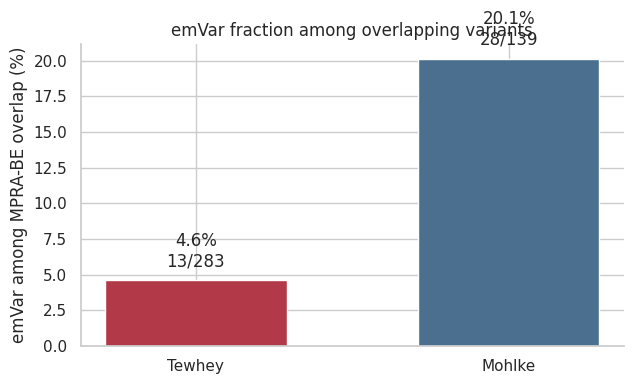

In [7]:
frac_rows = []
for dataset in ['Tewhey', 'Mohlke']:
    sub = summary[summary['dataset'].eq(dataset)]
    em = sub[sub['class'].eq('emVar')]['with_BE_count'].iloc[0]
    total = sub['with_BE_count'].sum()
    frac_rows.append({'dataset': dataset, 'emVar_with_BE': em, 'total_with_BE': total, 'fraction': em / total if total else np.nan})
frac_df = pd.DataFrame(frac_rows)
display(frac_df)

fig, ax = plt.subplots(figsize=(6.5, 4))
colors = ['#B23A48', '#4B6F8F']
ax.bar(frac_df['dataset'], frac_df['fraction'] * 100, color=colors, width=0.58)
for i, row in frac_df.iterrows():
    ax.text(i, row['fraction'] * 100 + 0.7, f"{row['fraction']*100:.1f}%\n{int(row['emVar_with_BE'])}/{int(row['total_with_BE'])}", ha='center', va='bottom')
ax.set_ylabel('emVar among MPRA-BE overlap (%)')
ax.set_title('emVar fraction among overlapping variants')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## MPRA Effect vs BE Signal

These scatter plots match the main dashboard: Tewhey uses MPRA `logFC Skew`, Mohlke uses MPRA `log2FC`, and points are colored by MPRA emVar status.

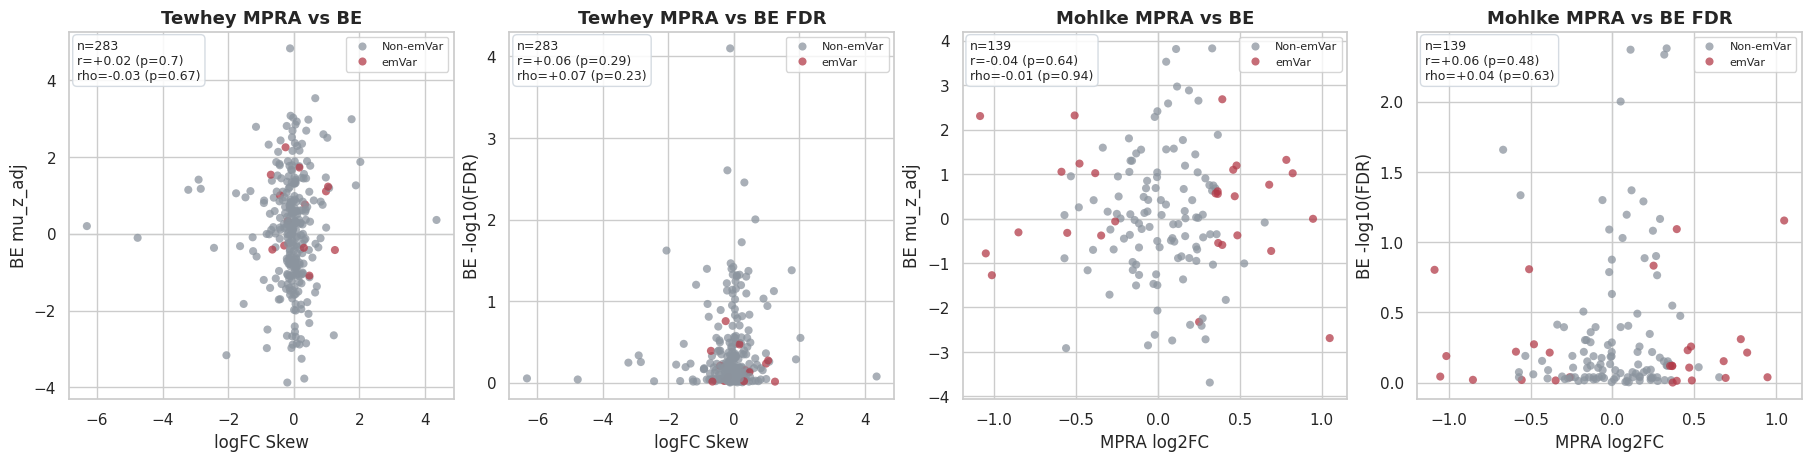

In [8]:
def corr_text(df, x, y):
    sub = df[[x, y]].dropna()
    if len(sub) < 3 or sub[x].nunique() < 2 or sub[y].nunique() < 2:
        return f'n={len(sub):,}'
    pr = pearsonr(sub[x], sub[y])
    sr = spearmanr(sub[x], sub[y])
    return f"n={len(sub):,}\nr={pr.statistic:+.2f} (p={pr.pvalue:.2g})\nrho={sr.statistic:+.2f} (p={sr.pvalue:.2g})"

def scatter_panel(ax, df, x, y, group_col, title, xlabel, ylabel):
    sub = df[[x, y, group_col]].dropna()
    sns.scatterplot(data=sub, x=x, y=y, hue=group_col, hue_order=BINARY_ORDER, palette=BINARY_PALETTE, s=34, alpha=0.74, linewidth=0, ax=ax)
    ax.axvline(0, color='#C9D1D9', lw=0.9, zorder=0)
    if y == BE_MU:
        ax.axhline(0, color='#C9D1D9', lw=0.9, zorder=0)
    ax.set_title(title, fontsize=13, weight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.text(0.02, 0.98, corr_text(df, x, y), transform=ax.transAxes, ha='left', va='top', fontsize=9, bbox=dict(facecolor='white', edgecolor='#D0D7DE', alpha=0.88, boxstyle='round,pad=0.35'))
    ax.legend(fontsize=8, frameon=True, loc='best', title='')

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), constrained_layout=True)
scatter_panel(axes[0], calls, TEWHEY_SKEW_FC, BE_MU, 'Tewhey_emVar_class', 'Tewhey MPRA vs BE', 'logFC Skew', 'BE mu_z_adj')
scatter_panel(axes[1], calls, TEWHEY_SKEW_FC, BE_LOGFDR, 'Tewhey_emVar_class', 'Tewhey MPRA vs BE FDR', 'logFC Skew', 'BE -log10(FDR)')
scatter_panel(axes[2], calls, MOHLKE_FC, BE_MU, 'Mohlke_emVar_class', 'Mohlke MPRA vs BE', 'MPRA log2FC', 'BE mu_z_adj')
scatter_panel(axes[3], calls, MOHLKE_FC, BE_LOGFDR, 'Mohlke_emVar_class', 'Mohlke MPRA vs BE FDR', 'MPRA log2FC', 'BE -log10(FDR)')
plt.show()

## BE Signal by MPRA emVar Status

The boxplots ask whether BE signal is shifted among MPRA emVars compared with MPRA non-emVars in the overlapping variants.

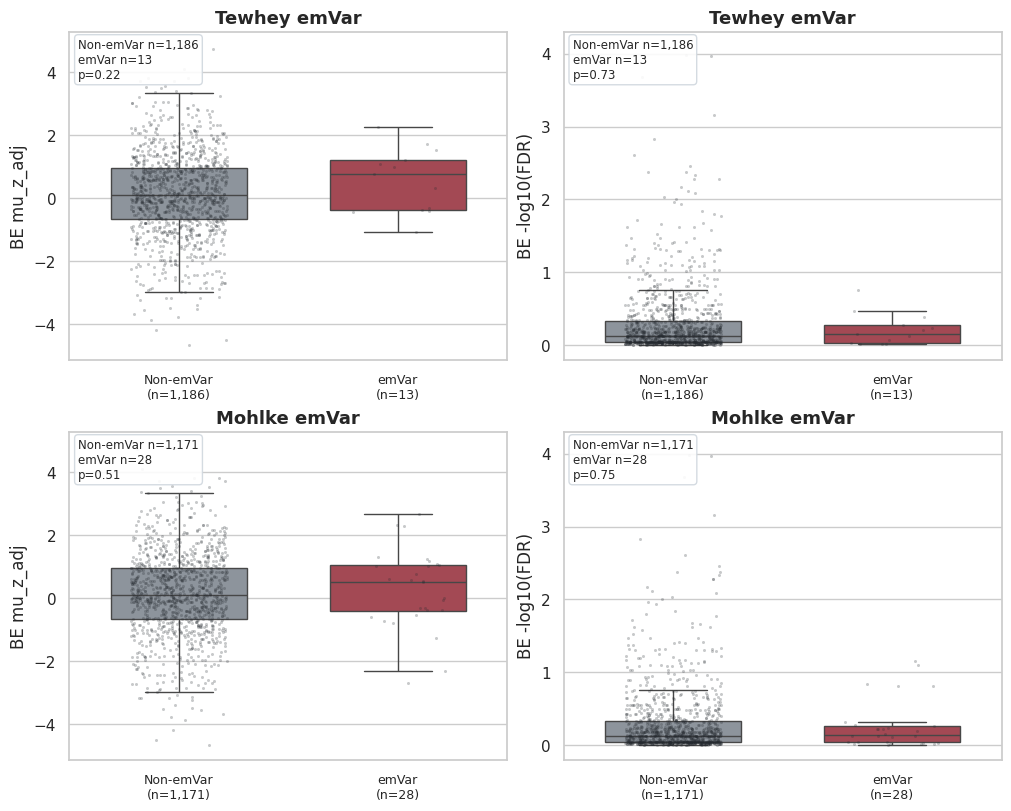

In [9]:
def test_text(df, group_col, y):
    sub = df[[group_col, y]].dropna().copy()
    emvar = sub.loc[sub[group_col].eq('emVar'), y]
    non = sub.loc[sub[group_col].eq('Non-emVar'), y]
    if len(emvar) == 0 or len(non) == 0:
        return 'Wilcoxon: n/a'
    stat = mannwhitneyu(non, emvar, alternative='two-sided')
    return f"Non-emVar n={len(non):,}\nemVar n={len(emvar):,}\np={stat.pvalue:.2g}"

def box_panel(ax, df, group_col, y, title, ylabel):
    sub = df[[group_col, y]].dropna()
    sns.boxplot(data=sub, x=group_col, y=y, order=BINARY_ORDER, hue=group_col, hue_order=BINARY_ORDER, palette=BINARY_PALETTE, showfliers=False, dodge=False, legend=False, width=0.62, ax=ax)
    sns.stripplot(data=sub, x=group_col, y=y, order=BINARY_ORDER, color='#24292F', alpha=0.25, size=2.2, jitter=0.22, ax=ax)
    counts = sub[group_col].value_counts().to_dict()
    ax.set_xticks(range(len(BINARY_ORDER)))
    ax.set_xticklabels([f"{label}\n(n={counts.get(label, 0):,})" for label in BINARY_ORDER], fontsize=9)
    ax.set_title(title, fontsize=13, weight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(ylabel)
    ax.text(0.02, 0.98, test_text(df, group_col, y), transform=ax.transAxes, ha='left', va='top', fontsize=8.5, bbox=dict(facecolor='white', edgecolor='#D0D7DE', alpha=0.9, boxstyle='round,pad=0.3'))

fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
box_panel(axes[0, 0], calls, 'Tewhey_emVar_class', BE_MU, 'Tewhey emVar', 'BE mu_z_adj')
box_panel(axes[0, 1], calls, 'Tewhey_emVar_class', BE_LOGFDR, 'Tewhey emVar', 'BE -log10(FDR)')
box_panel(axes[1, 0], calls, 'Mohlke_emVar_class', BE_MU, 'Mohlke emVar', 'BE mu_z_adj')
box_panel(axes[1, 1], calls, 'Mohlke_emVar_class', BE_LOGFDR, 'Mohlke emVar', 'BE -log10(FDR)')
plt.show()